# Principal Component Analysis

## Imports

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data

Breast cancer wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Karakteristieken:**

    :Aantal cases: 569

    :Aantal Attributen: 30 (!) numerieke voorspellende attributen en de klasse

    :Informatie mbt de attributen:
        - radius (mean of distances from center to points on the perimeter)
        - texture (standard deviation of gray-scale values)
        - perimeter
        - area
        - smoothness (local variation in radius lengths)
        - compactness (perimeter^2 / area - 1.0)
        - concavity (severity of concave portions of the contour)
        - concave points (number of concave portions of the contour)
        - symmetry
        - fractal dimension ("coastline approximation" - 1)

        De gemiddelde, standaardfout en de "slechtste" of grootste (gemiddelde van de drie 
        slechtste/grootste waarden) van deze kenmerken werden berekend voor elke afbeelding,
        wat resulteert in 30 kenmerken. Bijvoorbeeld, veld 0 is Mean Radius, veld 10 is 
        Radius SE, veld 20 is Worst Radius.

        - class:
                - WDBC-Malignant
                - WDBC-Benign

    :Samenvatting van de statistieken:

    ===================================== ====== ======
                                           Min    Max
    ===================================== ====== ======
    radius (mean):                        6.981  28.11
    texture (mean):                       9.71   39.28
    perimeter (mean):                     43.79  188.5
    area (mean):                          143.5  2501.0
    smoothness (mean):                    0.053  0.163
    compactness (mean):                   0.019  0.345
    concavity (mean):                     0.0    0.427
    concave points (mean):                0.0    0.201
    symmetry (mean):                      0.106  0.304
    fractal dimension (mean):             0.05   0.097
    radius (standard error):              0.112  2.873
    texture (standard error):             0.36   4.885
    perimeter (standard error):           0.757  21.98
    area (standard error):                6.802  542.2
    smoothness (standard error):          0.002  0.031
    compactness (standard error):         0.002  0.135
    concavity (standard error):           0.0    0.396
    concave points (standard error):      0.0    0.053
    symmetry (standard error):            0.008  0.079
    fractal dimension (standard error):   0.001  0.03
    radius (worst):                       7.93   36.04
    texture (worst):                      12.02  49.54
    perimeter (worst):                    50.41  251.2
    area (worst):                         185.2  4254.0
    smoothness (worst):                   0.071  0.223
    compactness (worst):                  0.027  1.058
    concavity (worst):                    0.0    1.252
    concave points (worst):               0.0    0.291
    symmetry (worst):                     0.156  0.664
    fractal dimension (worst):            0.055  0.208
    ===================================== ====== ======

In [2]:
df = pd.read_csv('../../DATA/cancer_tumor_data_features.csv')

In [3]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


-----

## Manueel bepalen van de PCA


### Schalen van de Data (gemiddelde naar nul brengen)

In [4]:
from sklearn.preprocessing import StandardScaler

In [5]:
scaler = StandardScaler()

In [6]:
scaled_X = scaler.fit_transform(df)

In [7]:
scaled_X

array([[ 1.09706398, -2.07333501,  1.26993369, ...,  2.29607613,
         2.75062224,  1.93701461],
       [ 1.82982061, -0.35363241,  1.68595471, ...,  1.0870843 ,
        -0.24388967,  0.28118999],
       [ 1.57988811,  0.45618695,  1.56650313, ...,  1.95500035,
         1.152255  ,  0.20139121],
       ...,
       [ 0.70228425,  2.0455738 ,  0.67267578, ...,  0.41406869,
        -1.10454895, -0.31840916],
       [ 1.83834103,  2.33645719,  1.98252415, ...,  2.28998549,
         1.91908301,  2.21963528],
       [-1.80840125,  1.22179204, -1.81438851, ..., -1.74506282,
        -0.04813821, -0.75120669]])

In [8]:
# In het kader van Principal Component Analysis (PCA) is het belangrijk om de data eerst te 
# standaardiseren of te schalen, vooral als de kenmerken verschillende eenheden of sterk 
# variërende schalen hebben. Dit zorgt ervoor dat geen enkel kenmerk onevenredig veel invloed 
# heeft op de resultaten van de PCA.

# Het aftrekken van het gemiddelde van elk kenmerk (in dit geval met scaled_X.mean(axis=0)) 
# is een manier om de data te centreren rond nul. Dit is een standaard stap in het 
# standaardisatieproces, waarbij het doel is de gemiddelde waarde van elk kenmerk tot nul 
# te reduceren. In het geval van reeds geschaalde data, zoals hier aangegeven, is deze stap 
# mogelijk overbodig, maar het is een cruciale stap voor niet-geschaalde data om ervoor te 
# zorgen dat elk kenmerk gelijkmatig bijdraagt aan de PCA.

# Omdat we de data hebben geschaald, zal dit hier dus geen verandering teweegbrengen.
# Het is hier vermeld omdat je dit moet doen voor niet-geschaalde data!
scaled_X -= scaled_X.mean(axis=0)

In [9]:
scaled_X

array([[ 1.09706398, -2.07333501,  1.26993369, ...,  2.29607613,
         2.75062224,  1.93701461],
       [ 1.82982061, -0.35363241,  1.68595471, ...,  1.0870843 ,
        -0.24388967,  0.28118999],
       [ 1.57988811,  0.45618695,  1.56650313, ...,  1.95500035,
         1.152255  ,  0.20139121],
       ...,
       [ 0.70228425,  2.0455738 ,  0.67267578, ...,  0.41406869,
        -1.10454895, -0.31840916],
       [ 1.83834103,  2.33645719,  1.98252415, ...,  2.28998549,
         1.91908301,  2.21963528],
       [-1.80840125,  1.22179204, -1.81438851, ..., -1.74506282,
        -0.04813821, -0.75120669]])

In [22]:
scaled_X.mean()

4.7869018519280325e-18

In [25]:
# elscaled_X.mean(axis=0)ke dimensie heeft een gemiddelde rond nul
scaled_X.mean(axis=0)

array([ 6.24378502e-18,  1.87313551e-17,  2.49751401e-17,  6.24378502e-18,
        4.99502802e-17,  1.24875700e-17,  2.49751401e-17, -4.99502802e-17,
       -2.49751401e-17,  1.24875700e-17,  0.00000000e+00,  2.34141938e-17,
       -1.24875700e-17, -1.24875700e-17, -1.56094626e-17, -1.24875700e-17,
        1.87313551e-17,  0.00000000e+00,  0.00000000e+00, -6.24378502e-18,
       -1.24875700e-17,  1.24875700e-17,  3.74627101e-17,  0.00000000e+00,
        3.74627101e-17,  2.49751401e-17,  2.49751401e-17,  0.00000000e+00,
        3.74627101e-17,  2.49751401e-17])

### Berekenen van de Covariantie Matrix

In [28]:
covariance_matrix = np.cov(scaled_X, rowvar=False)

# Uitleg:
# In de context van datasets zoals scaled_X stelt typisch elke rij een 
# observatie (bijvoorbeeld een patiënt, een klant, enz.) voor en elke kolom 
# een feature (zoals leeftijd, inkomen, enz.). Met rowvar=False wordt de covariantiematrix 
# berekend op basis van de kolommen en niet over de rijen - dus niet over observaties maar
# over features, wat onze bedoeling is.

In [31]:
# Bereken Eigen Vectors and Eigen Values via de lineaire algebra library van Numpy
eigen_values, eigen_vectors = np.linalg.eig(covariance_matrix)
# we hebben nu 30 Principal Components...

In [33]:
# Kies een aantal principal components
num_components=2   # Van 30 features naar 2 -> reductie om te kunnen visualiseren!

In [34]:
# Orden de indices van de eigenwaarden in afnemende volgorde en selecteert de top 
# num_components indices
sorted_key = np.argsort(eigen_values)[::-1][:num_components]

# Uitleg van de code:
# np.argsort(eigen_values): Retourneert de indices die de eigenwaarden zouden sorteren in oplopende volgorde.
# [::-1]: Keert de volgorde van de gesorteerde indices om, waardoor ze in afnemende volgorde van de eigenwaarden komen.
# [:num_components]: Selecteert de eerste num_components indices na de sortering, wat overeenkomt met de indices van de hoogste eigenwaarden.

# Dit wordt vaak gebruikt in PCA om de indices van de eigenwaarden te vinden die 
# overeenkomen met de top num_components principiële componenten, 
# wat betekent dat deze componenten het grootste deel van de variatie in de dataset verklaren.

In [38]:
# Verkrijg num_components Eigen Values and Eigen Vectors
eigen_values, eigen_vectors = eigen_values[sorted_key], eigen_vectors[:, sorted_key]

# Uitleg:  
# Deze regel code herordent de eigenwaarden en de bijbehorende eigenvectoren op basis van de 
# keys verkregen uit sorted_key.

# eigen_values[sorted_key]: selecteert en herorden de eigenwaarden volgens de indices in 
# sorted_key. Aangezien sorted_key de indices van de eigenvalues in afnemende volgorde bevat, 
# worden de eigenvalues nu ook afnemend gerangschikt.
# eigen_vectors[:, sorted_key]: selecteert en herordent de kolommen van de matrix 
# eigen_vectors. Elke eigenvector in eigen_vectors komt overeen met een eigenvalue in eigen_values, 
# dus het is belangrijk om beide in dezelfde volgorde te houden.

# Het resultaat is dat zowel de eigenvalues als de eigenvectoren zijn gerangschikt van 
# groot naar klein (of van meest significante naar minst significante in termen van de 
# hoeveelheid verklaarde variatie in de data). Dit is een gebruikelijke stap in PCA om te 
# focussen op de belangrijkste componenten.

In [39]:
# Het dotproduct van de originele data en eigenvectoren zijn de waarden van de hoofdcomponenten
# Dit is de "projectie" stap van de originele punten op eigen vectors:
# scaled_X heeft 30 features, en deze worden geprojecteerd op de top 2 eigen vectors
# !! Na deze projectie spreken we van de principal components en niet langer de eigen vectors
principal_components=np.dot(scaled_X,eigen_vectors)

In [40]:
# we hebben nu de dataset in 2 nieuwe dimensies: de principal components
principal_components.shape

(569, 2)

Text(0, 0.5, 'Second Principal Component')

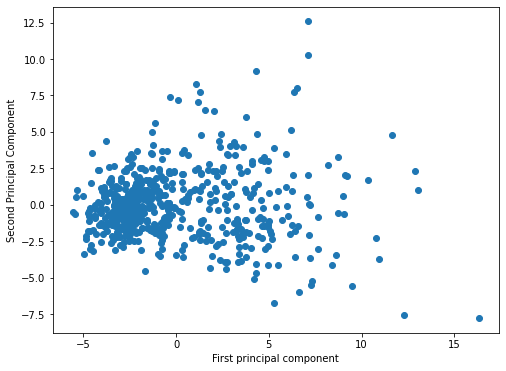

In [29]:

plt.figure(figsize=(8,6))
plt.scatter(principal_components[:,0],principal_components[:,1])
plt.xlabel('First principal component')
plt.ylabel('Second Principal Component')

## Geef deze punten weer in functie van de maligniteit uit de dataset

In [43]:
# deze dataset is ingebouwd in sklearn, dus we kunnen het label daar halen
from sklearn.datasets import load_breast_cancer

In [45]:
# HIERVOOR HEB JE INTERNET ACCESS EN FIREWALL TOEGANG NODIG OP JOUW PC
cancer_dictionary = load_breast_cancer()

In [46]:
cancer_dictionary.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [52]:
# print(cancer_dictionary['DESCR'])

In [47]:
cancer_dictionary['target']

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,

Text(0, 0.5, 'Second Principal Component')

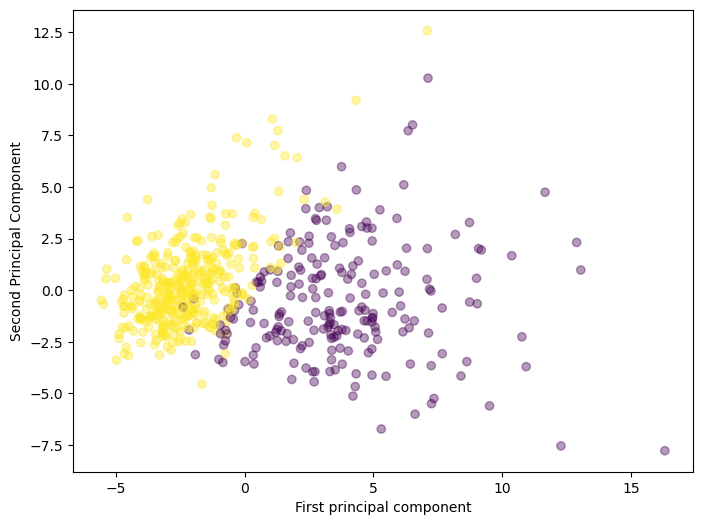

In [50]:
plt.figure(figsize=(8,6))
plt.scatter(principal_components[:,0],principal_components[:,1],c=cancer_dictionary['target'], alpha=0.4)
plt.xlabel('First principal component')
plt.ylabel('Second Principal Component')

We hebben dus een goede scheiding tussen de klasses op basis van de 2 principal components!
Er is dus nog steeds goede informatie inzake de scheiding tussen de klassen aanwezig in de 
2 principal components.  We waren dus in staat om een dataset met 30 features te reduceren tot 
2 Principal Components met behoud van de informatie om de dataset te scheiden.  Je hebt dus niet
alle details van de 30 originele features nodig om voldoende informatie te hebben om de data 
te scheiden.  Je kan dus eerst PCA gebruiken alvorens je een classificatie uitvoert, en zal 
gelijkaardige performantie krijgen.  Een voordeel: je hebt slechts 1/15e van de originele data nodig...